# 02. Pré-processamento, Features Cíclicas e Particionamento Temporal
## Trabalho Prático de Deep Learning (2026/2) — Prof. Dr. Sérgio Canuto
**Objetivo:** Construir o pipeline anti-leakage com extração cíclica, particionamento cronológico estrito (sem shuffle) e ajuste do `ColumnTransformer` apenas no treinamento.


In [1]:
import sys
import os
for p in ['.', '..', '../..']:
    if os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_pipeline import (
    load_vra_dataset, clean_and_prepare_vra,
    split_chronological, build_and_fit_preprocessor,
    transform_splits
)


### 1. Higienização e Engenharia de Features Cíclicas


In [2]:
data_path = 'data/raw/vra_amostra_2023.csv' if os.path.exists('data/raw/vra_amostra_2023.csv') else '../data/raw/vra_amostra_2023.csv'
df_raw = load_vra_dataset(data_path)
df_clean = clean_and_prepare_vra(df_raw, delay_threshold_min=15)
print(f"Voos higienizados: {len(df_clean)}")
df_clean[['PartidaPrevista', 'TempoVooPrevistoMin', 'hora_sin', 'hora_cos', 'target_bin']].head()


Voos higienizados: 5753


,PartidaPrevista,TempoVooPrevistoMin,hora_sin,hora_cos,target_bin
0,2023-01-01 06:00:00,147.0,1.000000,6.123234e-17,1
1,2023-01-01 06:43:04,103.0,0.982450,-1.865240e-01,1
2,2023-01-01 07:04:36,175.0,0.961262,-2.756374e-01,0
3,2023-01-01 07:26:08,134.0,0.930418,-3.665012e-01,0
4,2023-01-01 07:47:40,148.0,0.892979,-4.500984e-01,0


### 2. Visualização das Transformações Cíclicas de Horário


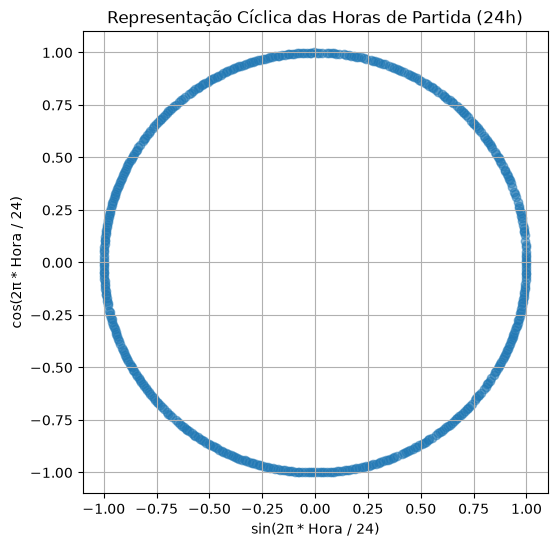

In [3]:
plt.figure(figsize=(6, 6))
plt.scatter(df_clean['hora_sin'].iloc[:500], df_clean['hora_cos'].iloc[:500], alpha=0.5, c='#1f77b4')
plt.title('Representação Cíclica das Horas de Partida (24h)')
plt.xlabel('sin(2π * Hora / 24)')
plt.ylabel('cos(2π * Hora / 24)')
plt.grid(True)
plt.show()


### 3. Divisão Cronológica Estrita (70% Treino, 15% Validação, 15% Teste)


In [4]:
train_df, val_df, test_df = split_chronological(df_clean, train_ratio=0.70, val_ratio=0.15)
print(f"Período Treino:    {train_df['PartidaPrevista'].min()} até {train_df['PartidaPrevista'].max()} ({len(train_df)} amostras)")
print(f"Período Validação: {val_df['PartidaPrevista'].min()} até {val_df['PartidaPrevista'].max()} ({len(val_df)} amostras)")
print(f"Período Teste:     {test_df['PartidaPrevista'].min()} até {test_df['PartidaPrevista'].max()} ({len(test_df)} amostras)")

assert train_df['PartidaPrevista'].max() <= val_df['PartidaPrevista'].min()
assert val_df['PartidaPrevista'].max() <= test_df['PartidaPrevista'].min()
print("--> ASSERÇÃO CONFIRMADA: Nenhuma sobreposição temporal entre as partições!")


Período Treino:    2023-01-01 06:00:00 até 2023-03-05 04:34:52 (4027 amostras)
Período Validação: 2023-03-05 04:56:24 até 2023-03-18 17:01:14 (863 amostras)
Período Teste:     2023-03-18 17:22:46 até 2023-03-31 23:00:00 (863 amostras)
--> ASSERÇÃO CONFIRMADA: Nenhuma sobreposição temporal entre as partições!


### 4. Ajuste do Pipeline (ColumnTransformer) Exclusivamente no Treino


In [5]:
num_cols = ['TempoVooPrevistoMin', 'hora_sin', 'hora_cos', 'dia_semana_sin', 'dia_semana_cos', 'mes_sin', 'mes_cos']
cat_cols = ['ICAOEmpresaAerea', 'CodigoTipoLinha', 'ICAOAerodromoOrigem', 'ICAOAerodromoDestino']
feature_cols = num_cols + cat_cols

preprocessor = build_and_fit_preprocessor(train_df, num_cols, cat_cols)
X_train, y_train, X_val, y_val, X_test, y_test = transform_splits(
    preprocessor, train_df, val_df, test_df, feature_cols, 'target_bin'
)

print(f"Formato X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Formato X_val:   {X_val.shape}   | y_val:   {y_val.shape}")
print(f"Formato X_test:  {X_test.shape}  | y_test:  {y_test.shape}")


Formato X_train: (4027, 36) | y_train: (4027,)
Formato X_val:   (863, 36)   | y_val:   (863,)
Formato X_test:  (863, 36)  | y_test:  (863,)
